# ENGR 510: Introduction to Non-Neural Network ML

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# For importing the MNIST data set:
from sklearn.datasets import fetch_openml

# Scikit-learn PCA model:
from sklearn.decomposition import PCA

# Scikit-learn LDA model:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Scikit-learn SVM classifier:
from sklearn.svm import LinearSVC

# Scikit-learn decision tree classifier:
from sklearn.tree import DecisionTreeClassifier

First, let us import and visualize the MNIST data set by running the following code block.

**Please run the cell below. DO NOT edit this cell.**

MNIST data loaded succesfully!
Image data: X.shape = (70000, 784)
Label data: y.shape = (70000,)



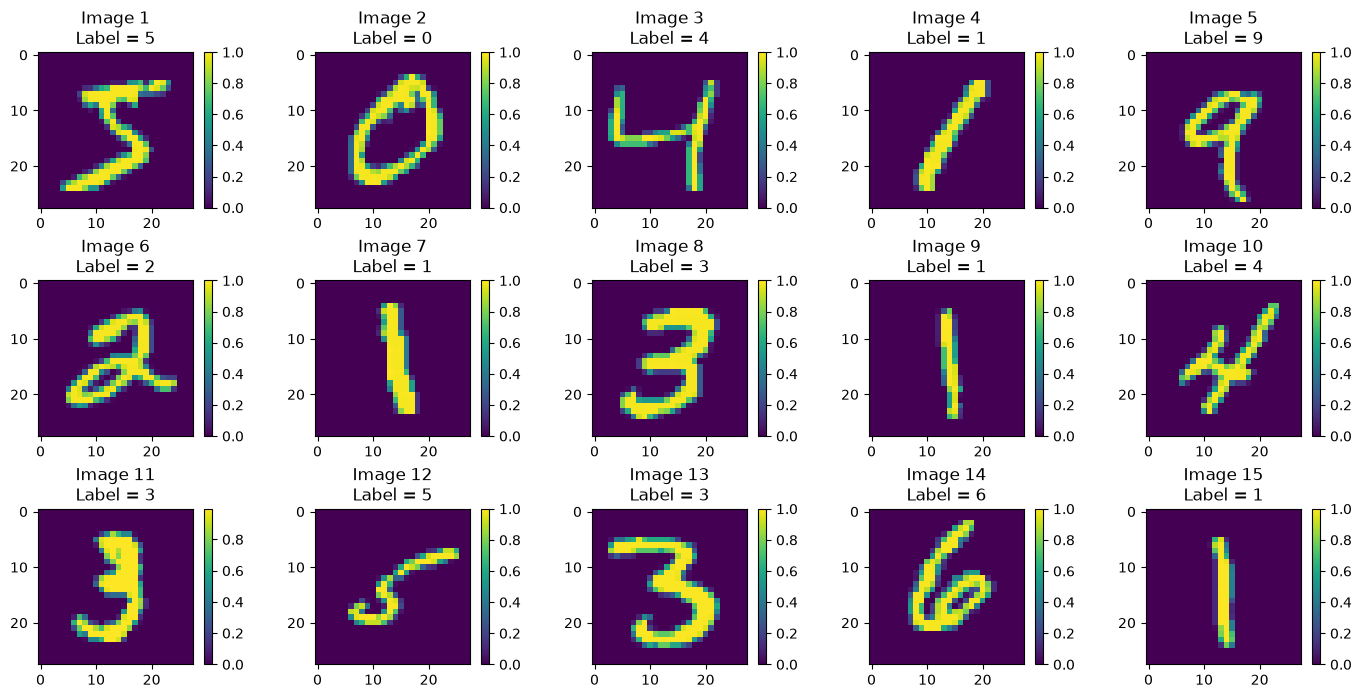

In [42]:
# Load the MNIST data:
mnist = fetch_openml("mnist_784", parser="auto")
X = np.array(mnist.data) / 255.0  # Scale the data to [0, 1]
y = np.array(mnist.target)

# Print some data information:
print("MNIST data loaded succesfully!")
print(f"Image data: X.shape = {X.shape}")
print(f"Label data: y.shape = {y.shape}")
print()

# Plot some of the MNIST images.
plt.figure(figsize=(14, 7))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.title(f"Image {i + 1}\nLabel = {y[i]}")
    plt.imshow(X[i, :].reshape(28, 28))
    plt.colorbar()
plt.tight_layout()
plt.show()

# Mean center the data for PCA.
X = X - np.mean(X, axis=0)

Notice that there are 70,000 images total, with each image being 28 x 28 pixels, or 784 pixels total.

Each image comes with a corresponding label, i.e. a number that indicates what digit is inside the image.

## Part 1: Dimensionality Reduction with PCA

In [43]:
### TODO: Perform SVD analysis.
U, s, Vt = np.linalg.svd(X, full_matrices=False)

# Transpose Vt to get V
V = Vt.T

# Check the dimensions
print("U shape:", U.shape)
print("Singular values shape:", s.shape)
print("V shape:", V.shape)


U shape: (70000, 784)
Singular values shape: (784,)
V shape: (784, 784)


A1 shape: (784, 5)


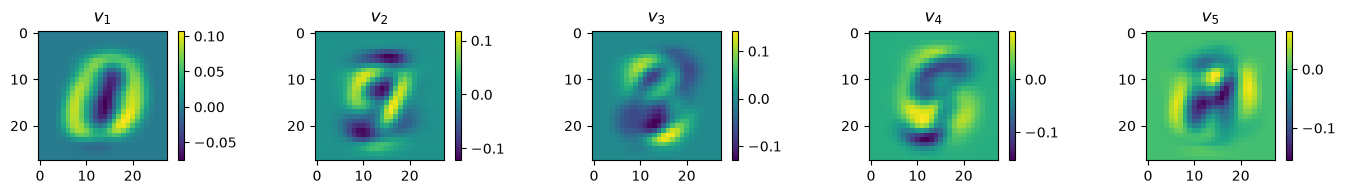

In [44]:
### TODO: Save the first five dominant modes.

A1 = V[:, :5]

# Check the result
print("A1 shape:", A1.shape)


# # OPTIONAL: Plot columns of V.
plt.figure(figsize=(14, 2))
for i, v in enumerate(A1.T):
    plt.subplot(1, 5, i + 1)
    plt.title(f"$v_{i + 1}$")
    plt.imshow(v.reshape(28, 28))
    plt.colorbar()
plt.tight_layout()
plt.show()

In [45]:
### TODO: Reconstruct the first MNIST image.
r_values = [5, 50, 100, 300]
x = X[0]


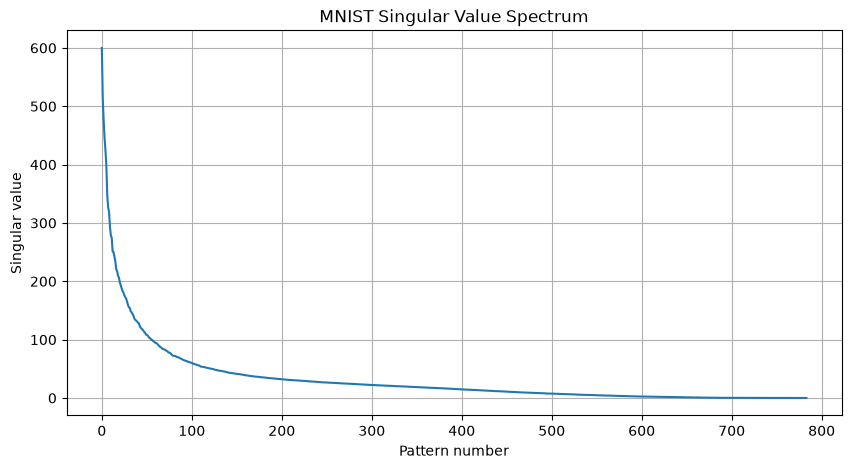

A2: 331
Variance retained: 99.00550292572767 %


In [46]:
### TODO: Plot the singular values.
plt.figure(figsize=(10, 5))
plt.plot(s)

plt.xlabel("Pattern number")
plt.ylabel("Singular value")
plt.title("MNIST Singular Value Spectrum")
plt.grid(True)
plt.show()

### TODO: Compute the rank truncation r.
# Square the singular values to measure variance contribution
variance = s ** 2

# Calculate cumulative percentage of variance retained
cumulative_variance = np.cumsum(variance) / np.sum(variance)

# Find the smallest number of patterns that retain at least 99%
A2 = int(np.searchsorted(cumulative_variance, 0.99) + 1)

print("A2:", A2)
print("Variance retained:", cumulative_variance[A2 - 1] * 100, "%")


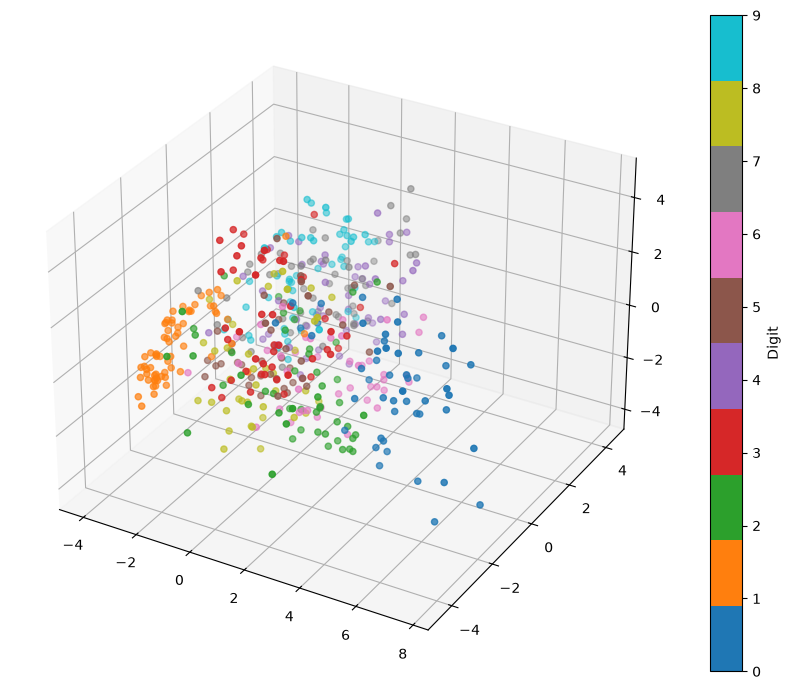

In [47]:
### TODO: Project data onto the 350 leading V modes.
X_pca = X @ V[:, :350]

### TODO: Plot projected data in 3-D.
### Once you define X_pca, uncomment and run the following plotting code!

num_plot = 500
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")

sc = ax.scatter(
    X_pca[:num_plot, 0],
    X_pca[:num_plot, 1],
    X_pca[:num_plot, 2],
    c=y[:num_plot].astype(int),
    cmap="tab10",
    marker="o",
)

plt.colorbar(sc, ax=ax, label="Digit")
plt.tight_layout()
plt.show()

## Part 2: MNIST Digit Classification

First, obtain the rank $r=350$ PCA-projected data.

**Please run the cell below. DO NOT edit this cell.**

In [48]:
# Use Scikit-learn PCA model to reduce the data.
pca = PCA(n_components=350)
X_pca = pca.fit_transform(X)

print(f"PCA image data: X_pca.shape = {X_pca.shape}")
print(f"Label data: y.shape = {y.shape}")

PCA image data: X_pca.shape = (70000, 350)
Label data: y.shape = (70000,)


The following code has been provided to help you with digit extraction and train / test splitting.

Feel free to use or not use this code, but please read the documentation carefully!

In [49]:
def get_digit_data(
    X: np.ndarray,
    y: np.ndarray,
    digit_list: list,
    n_test: int,
):
    """
    Helper function that takes the given data+labels, extracts the data+labels
    containing the desired digits, and returns a training / testing data split.

    Args:
        X = (n_samples, n_features) np.ndarray of data.
        y = (n_samples,) np.ndarray of corresponding labels.
        digit_list = list of desired MNIST digits to filter out.
        n_test = integer number of digits to take for the test set.
            The first n_test digits are always taken for the test set.
    Returns:
        1. (n_train, n_features) np.ndarray of training data.
        2. (n_train,) np.ndarray of training data labels.
        3. (n_test, n_features) np.ndarray of test data.
        4. (n_test,) np.ndarray of test data labels.
    """
    inds_test = np.array([], dtype=int)
    inds_train = np.array([], dtype=int)

    for digit in digit_list:
        digit_inds = np.where(y.astype(int) == digit)[0]
        inds_test = np.union1d(inds_test, digit_inds[:n_test])
        inds_train = np.union1d(inds_train, digit_inds[n_test:])

    return X[inds_train], y[inds_train], X[inds_test], y[inds_test]

# EXAMPLE: How to form a training / testing data split on the PCA projected data
# using the digits 0, 9 while setting the first 100 samples aside per digit for testing.
X_train, y_train, X_test, y_test = get_digit_data(X_pca, y, digit_list=[0, 9], n_test=100)
print(f"Training data: X_train.shape = {X_train.shape}")
print(f"Training labels: y_train.shape = {y_train.shape} y_train = {y_train}")
print(f"Testing data: X_test.shape = {X_test.shape}")
print(f"Testing labels: y_test.shape = {y_test.shape} y_test[:10] = {y_test[:10]}")

Training data: X_train.shape = (13661, 350)
Training labels: y_train.shape = (13661,) y_train = ['9' '9' '0' ... '0' '9' '0']
Testing data: X_test.shape = (200, 350)
Testing labels: y_test.shape = (200,) y_test[:10] = ['0' '9' '9' '0' '9' '9' '0' '0' '9' '9']


In [50]:
### TODO: Implement classification accuracy percentage.
def compute_accuracy(y, y_true):
    """
    Args:
        y = (n_samples,) np.ndarray of computed labels.
        y_true = (n_samples,) np.ndarray of true labels.
    Returns:
        Classification accuracy percentage as a float.
    """
    accuracy = np.mean(y == y_true) * 100
    return float(accuracy)

In [51]:
# TODO: Fit an LDA model using the digits 3, 4.
X_train, y_train, X_test, y_test = get_digit_data(
      X_pca, y, [3, 4], 100
)

lda = LinearDiscriminantAnalysis()
# DO SOMETHING WITH lda!

y_train_predict = ...
y_test_predict = ...

train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

A3 = np.array([train_accuracy, test_accuracy])

In [52]:
# TODO: Fit an LDA model using the digits 3, 5, 9.
X_train, y_train, X_test, y_test = get_digit_data(
      X_pca, y, [3, 5, 9], 100
)

lda = LinearDiscriminantAnalysis()
# DO SOMETHING WITH lda!

# train model
lda.fit(X_train, y_train)

y_train_predict = lda.predict(X_train)
y_test_predict = lda.predict(X_test)

train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

A4 = np.array([train_accuracy, test_accuracy])

print("A4:", A4)

A4: [95.29634049 93.66666667]


In [53]:
# TODO: Fit an LDA model using all digit pairs.

from itertools import combinations

# Store results for each digit pair
results = []

# Loop through all 45 unique pairs
for digit1, digit2 in combinations(range(10), 2):

    # Reserve 500 images of each digit for testing
    X_train, y_train, X_test, y_test = get_digit_data(
        X_pca, y, [digit1, digit2], 500
    )

    # Create and train the LDA model
    lda = LinearDiscriminantAnalysis()
    lda.fit(X_train, y_train)

    # Predict the digits
    train_predictions = lda.predict(X_train)
    test_predictions = lda.predict(X_test)

    # Calculate accuracy percentages
    train_accuracy = compute_accuracy(train_predictions, y_train)
    test_accuracy = compute_accuracy(test_predictions, y_test)

    # Save pair and accuracy results
    results.append((digit1, digit2, train_accuracy, test_accuracy))

# Lowest test accuracy = hardest pair
hardest = min(results, key=lambda result: result[3])

# Highest test accuracy = easiest pair
easiest = max(results, key=lambda result: result[3])

# Store answers for the autograder
A5 = np.array([hardest[0], hardest[1]])
A6 = np.array([hardest[2], hardest[3]])

A7 = np.array([easiest[0], easiest[1]])
A8 = np.array([easiest[2], easiest[3]])

print("A5 - Hardest pair:", A5)
print("A6 - Hardest accuracies:", A6)
print("A7 - Easiest pair:", A7)
print("A8 - Easiest accuracies:", A8)


A5 - Hardest pair: [3 5]
A6 - Hardest accuracies: [96.12172796 95.5       ]
A7 - Easiest pair: [6 7]
A8 - Easiest accuracies: [99.80256663 99.7       ]


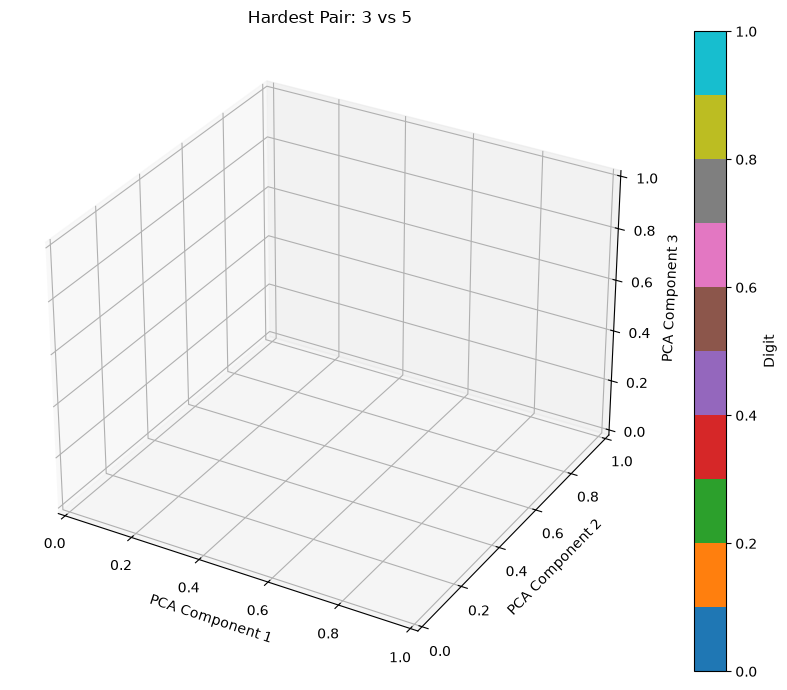

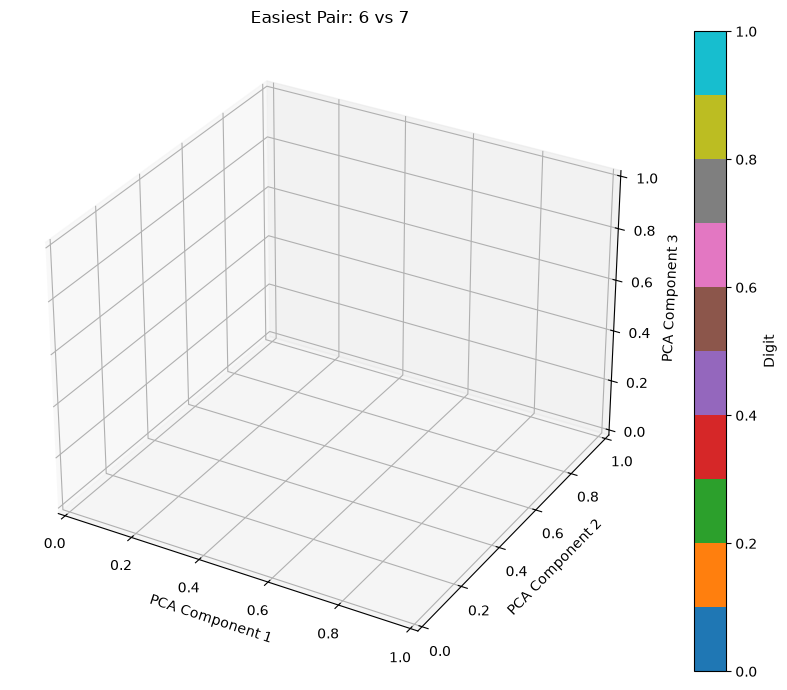

In [ ]:
# TODO: Plot the hardest digit pair and the easiest digit pair.

# Plot both pairs in 3D
for pair, title in [(A5, "Hardest"), (A7, "Easiest")]:

    # Get 500 images of each digit
    X_train, y_train, X_test, y_test = get_digit_data(
        X_pca, y, pair.tolist(), 500
    )

    # Combine both datasets for plotting
    X_plot = np.vstack((X_train, X_test))
    y_plot = np.concatenate((y_train, y_test))

    # Select up to 500 images of each digit
    selected = np.concatenate([
        #np.where(y_plot == digit)[0][:500]
        np.where(y_plot.astype(int) == digit)[0][:500]
        for digit in pair
    ])

    # Create the 3D plot
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(projection="3d")

    sc = ax.scatter(
        X_plot[selected, 0],
        X_plot[selected, 1],
        X_plot[selected, 2],
        c=y_plot[selected].astype(int),
        cmap="tab10",
        marker="o"
    )

    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.set_zlabel("PCA Component 3")
    ax.set_title(f"{title} Pair: {pair[0]} vs {pair[1]}")

    plt.colorbar(sc, ax=ax, label="Digit")
    plt.tight_layout()
    plt.show()


In [55]:
# TODO: Fit an SVM model using the digits 7, 9.

# Select digits 7 and 9, reserving 500 of each for testing
X_train, y_train, X_test, y_test = get_digit_data(
    X_pca, y, [7, 9], 500
)

# Create the SVM classifier
svm = LinearSVC()

# Train the model
svm.fit(X_train, y_train)

# Predict training and testing labels
y_train_predict = svm.predict(X_train)
y_test_predict = svm.predict(X_test)

# Calculate accuracy percentages
train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

# Save results for the autograder
A9 = np.array([train_accuracy, test_accuracy])

print("A9:", A9)


A9: [96.9662667 96.4      ]


In [56]:
# TODO: Fit an SVM model using the digits 1, 6.

# Select digits 1 and 6, reserving 500 of each for testing
X_train, y_train, X_test, y_test = get_digit_data(
    X_pca, y, [1, 6], 500
)

# Create the SVM classifier
svm = LinearSVC()

# Train the model using the training data
svm.fit(X_train, y_train)

# Predict the digits in both datasets
y_train_predict = svm.predict(X_train)
y_test_predict = svm.predict(X_test)

# Calculate training and testing accuracy
train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

# Store the results for the autograder
A10 = np.array([train_accuracy, test_accuracy])

print("A10:", A10)

A10: [100. 100.]


In [57]:

# TODO: Fit a decision tree using the digits 4, 9.

# Get digits 4 and 9, reserving 500 of each for testing
X_train, y_train, X_test, y_test = get_digit_data(
    X_pca, y, [4, 9], 500
)

# Create the decision tree model
tree = DecisionTreeClassifier(random_state=1234)

# Train the model using training data
tree.fit(X_train, y_train)

# Predict digits in training and testing data
y_train_predict = tree.predict(X_train)
y_test_predict = tree.predict(X_test)

# Calculate accuracy percentages
train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

# Store results for the autograder
A11 = np.array([train_accuracy, test_accuracy])

print("A11:", A11)

A11: [100.  89.]


In [58]:
# TODO: Fit a decision tree using the digits 0, 1.

# Get digits 0 and 1, reserving 500 of each for testing
X_train, y_train, X_test, y_test = get_digit_data(
    X_pca, y, [0, 1], 500
)

# Create the decision tree model
tree = DecisionTreeClassifier(random_state=1234)

# Train the model using training data
tree.fit(X_train, y_train)

# Predict digits in training and testing data
y_train_predict = tree.predict(X_train)
y_test_predict = tree.predict(X_test)

# Calculate accuracy percentages
train_accuracy = compute_accuracy(y_train_predict, y_train)
test_accuracy = compute_accuracy(y_test_predict, y_test)

# Store results for the autograder
A12 = np.array([train_accuracy, test_accuracy])

print("A12:", A12)

A12: [100.   99.6]
